# Chronoamperometry Across Geometries: Planar, Spherical & Cylindrical

## 1. Goal

Compare potential-step current density transients across `PlanarGeometry`, `SphericalGeometry`, and `CylindricalGeometry`, and observe how radial diffusion produces a non-zero steady-state current at spherical microelectrodes.

## 2. Physical Setup

We use the same redox couple ($D = 10^{-9}\text{ m}^2/\text{s}$, $c^* = 1\text{ mM}$, $n = 1$) and apply a $5\text{ s}$ step to $-0.4\text{ V}$ at:
1. A planar macroelectrode ($A = 7.07 \times 10^{-6}\text{ m}^2$).
2. A spherical microelectrode ($r_0 = 25\,\mu\text{m}$).
3. A cylindrical wire microelectrode ($r_0 = 25\,\mu\text{m}$, $L = 1\text{ cm}$).

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa
from softpotato.geometry import CylindricalGeometry, PlanarGeometry, SphericalGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import Chronoamperometry, simulate

D = 1.0e-9
c_bulk = 1.0
n = 1
E0 = 0.0
r0 = 25.0e-6      # 25 um radius
length = 1.0e-2   # 1 cm cylinder length

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=n)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
nernst = NernstianEquilibrium(E0=E0, n=n)
ca = Chronoamperometry(E_step=-0.4, duration=5.0)

geometries = {
    "Planar": PlanarGeometry(area=7.07e-6),
    "Spherical (r0=25 um)": SphericalGeometry(r0=r0),
    "Cylindrical (r0=25 um)": CylindricalGeometry(r0=r0, length=length),
}

## 3. Simulation

We run `simulate()` for each geometry and normalize the current by each electrode's active surface area ($j = I / A$) so the flux densities can be compared directly.

In [2]:
results = {
    label: simulate(ca, [ox, red], geometry=geom, kinetics=nernst)
    for label, geom in geometries.items()
}

for label, res in results.items():
    area = geometries[label].surface_area
    print(f"{label:24s} | A = {area:.3e} m^2 | j(5 s) = {res.current[-1] / area:.3f} A/m^2")

Planar                   | A = 7.070e-06 m^2 | j(5 s) = -0.770 A/m^2
Spherical (r0=25 um)     | A = 7.854e-09 m^2 | j(5 s) = -4.636 A/m^2
Cylindrical (r0=25 um)   | A = 1.571e-06 m^2 | j(5 s) = -2.169 A/m^2


## 4. Diagnostics & Plots

We compare the simulated current densities against the exact analytical expressions (`cottrell()`, `cottrell_spherical()`, `cottrell_cylinder()`) and mark the spherical steady-state limit $j_{\text{ss}} = -n F D c^* / r_0$.

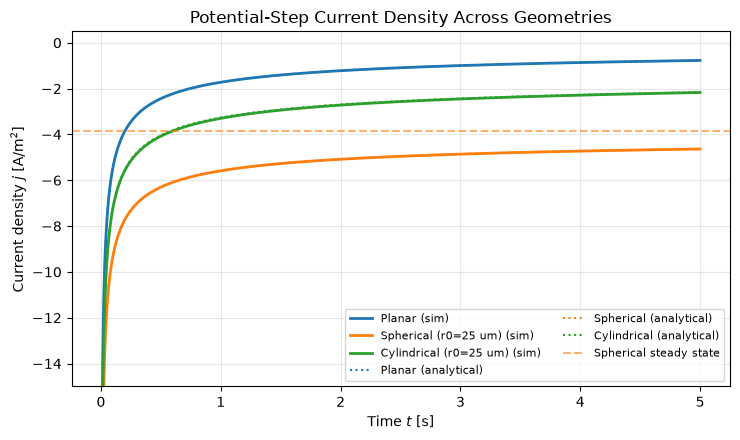

In [3]:
t = results["Planar"].time[1:]
j_planar_ana = -spa.cottrell(t, n=n, D=D, c_bulk=c_bulk, area=1.0)
j_sph_ana = -spa.cottrell_spherical(t, r=r0, n=n, D=D, c_bulk=c_bulk, area=geometries["Spherical (r0=25 um)"].surface_area) / geometries["Spherical (r0=25 um)"].surface_area
j_cyl_ana = -spa.cottrell_cylinder(t, r0=r0, n=n, D=D, c_bulk=c_bulk, length=length) / geometries["Cylindrical (r0=25 um)"].surface_area
j_sph_ss = -spa.microsphere_limiting_current(r0, n=n, D=D, c_bulk=c_bulk) / geometries["Spherical (r0=25 um)"].surface_area

fig, ax = plt.subplots(figsize=(7.5, 4.5))
colors = ["C0", "C1", "C2"]
for (label, res), c in zip(results.items(), colors):
    area = geometries[label].surface_area
    ax.plot(res.time[1:], res.current[1:] / area, color=c, lw=2, label=f"{label} (sim)")

ax.plot(t, j_planar_ana, ":", color="C0", lw=1.5, label="Planar (analytical)")
ax.plot(t, j_sph_ana, ":", color="C1", lw=1.5, label="Spherical (analytical)")
ax.plot(t, j_cyl_ana, ":", color="C2", lw=1.5, label="Cylindrical (analytical)")
ax.axhline(j_sph_ss, color="C1", ls="--", alpha=0.6, label="Spherical steady state")

ax.set_xlabel("Time $t$ [s]")
ax.set_ylabel("Current density $j$ [A/m$^2$]")
ax.set_title("Potential-Step Current Density Across Geometries")
ax.set_ylim(-15, 0.5)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- **Planar** current density decays monotonically as $t^{-1/2} \to 0$.
- **Spherical** diffusion accesses a 3D hemispherical volume, converging to a finite steady-state current density $j_{\text{ss}} = -n F D c^* / r_0$.
- **Cylindrical** diffusion decays much more slowly than planar ($\sim 1/\ln t$), sitting between planar and spherical behavior.
- **Next**: See [CV on a Spherical Microelectrode](../mechanisms/cv_nernst_spherical.ipynb) or the [Mass Transport Concepts](../../concepts/electrochemistry/transport.md).